In [ ]:
# Реализуйте высокочастотную фильтрацию на основе ядра Гаусса
# Реализуйте вычисление свертки с помощью преобразования Фурье
# Реализуйте удаление периодического шума с помощью преобразования Фурье

In [1]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt
from skimage.feature import peak_local_max

In [2]:
image = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)

<h1>Высокочастотная фильтрация на основе ядра Гаусса</h1>

(np.float64(-0.5), np.float64(786.5), np.float64(593.5), np.float64(-0.5))

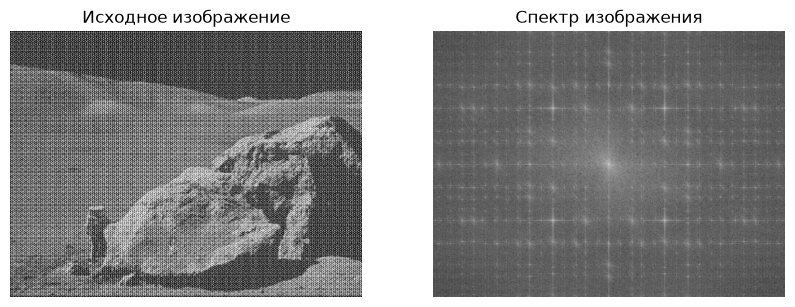

In [40]:
rows, cols = image.shape
dft = cv.dft(np.float32(image), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)
magnitude_spectrum_before = 20*np.log(cv.magnitude(dft_shift[:,:,0], dft_shift[:,:,1]) + 1)
s = 30
x, y = np.meshgrid(np.arange(cols), np.arange(rows))
gauss_mask = np.exp(-((x - cols//2)**2 + (y - rows//2)**2)/(2*s**2))
high_pass_mask = 1 - gauss_mask
dft_shift_hp = dft_shift * high_pass_mask[:, :, np.newaxis]

magnitude_spectrum_after = 20*np.log(cv.magnitude(dft_shift_hp[:,:,0], dft_shift_hp[:,:,1]) + 1)

f_ishift = np.fft.ifftshift(dft_shift_hp)
img_back_hp = cv.idft(f_ishift)
img_back_hp = cv.magnitude(img_back_hp[:,:,0], img_back_hp[:,:,1])
visual_result = cv.normalize(img_back_hp, None, 0, 255, cv.NORM_MINMAX).astype(np.uint8)

plt.figure(figsize=(10, 5))
plt.subplot(121)
plt.imshow(image, cmap='gray')
plt.title("Исходное изображение")
plt.axis('off')

plt.subplot(122)
plt.imshow(magnitude_spectrum_before, cmap='gray')
plt.title("Спектр изображения")
plt.axis('off')


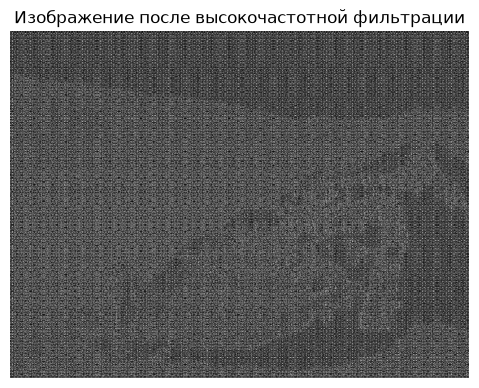

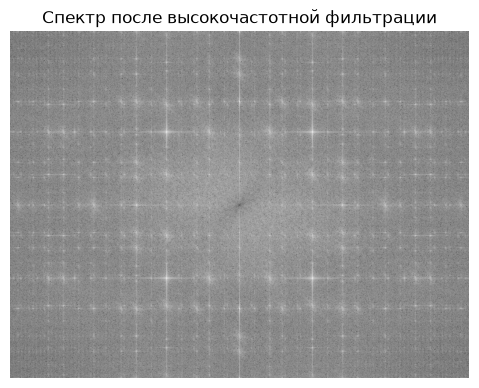

In [49]:
plt.figure(figsize=(10, 5))
plt.subplot(121)
plt.imshow(visual_result, cmap='gray')
plt.title("Изображение после высокочастотной фильтрации")
plt.tight_layout()
plt.axis('off')


plt.figure(figsize=(10, 5))
plt.subplot(122)
plt.imshow(magnitude_spectrum_after, cmap='gray')
plt.title("Спектр после высокочастотной фильтрации")
plt.tight_layout()
plt.axis('off')
plt.show()

<h1>Вычисление свертки с помощью преобразования Фурье</h1>

In [36]:
def dfourier_convolution(image, spatial_filter):
    M = np.float32(image)
    S = np.float32(spatial_filter)  
    rows, cols = M.shape
    sh, sw = S.shape
    
    S_prime = np.zeros_like(M)
    
    start_row = (rows - sh) // 2
    start_col = (cols - sw) // 2
    S_prime[start_row:start_row+sh, start_col:start_col+sw] = S
    
    S_prime = np.fft.fftshift(S_prime)
    
    M_dft = cv.dft(M, flags=cv.DFT_COMPLEX_OUTPUT)
    S_prime_dft = cv.dft(S_prime, flags=cv.DFT_COMPLEX_OUTPUT)
    
    result_dft = cv.mulSpectrums(M_dft, S_prime_dft, flags=0)
    
    M_S_complex = cv.idft(result_dft)
    
    M_S = M_S_complex[:, :, 0]
    
    return M_S


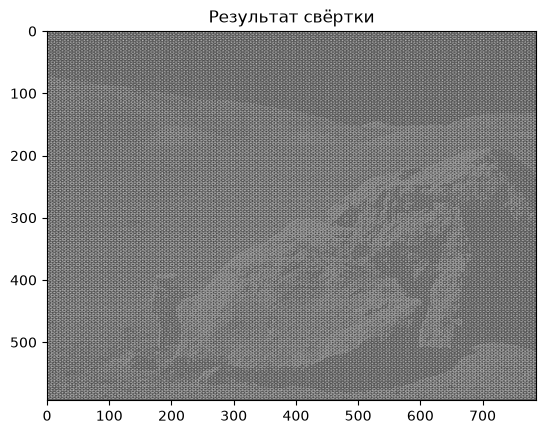

In [37]:
kernel = np.array([[ 0, -1,  0],
                   [-1,  5, -1],
                   [ 0, -1,  0]], dtype=np.float32)

res = dfourier_convolution(image, kernel)
res_visual = cv.normalize(res, None, 0, 255, cv.NORM_MINMAX).astype(np.uint8)
plt.title("Результат свёртки")
plt.imshow(res_visual, cmap='gray')

<h1>3. Удаление периодического шума с помощью преобразования Фурье </h1>

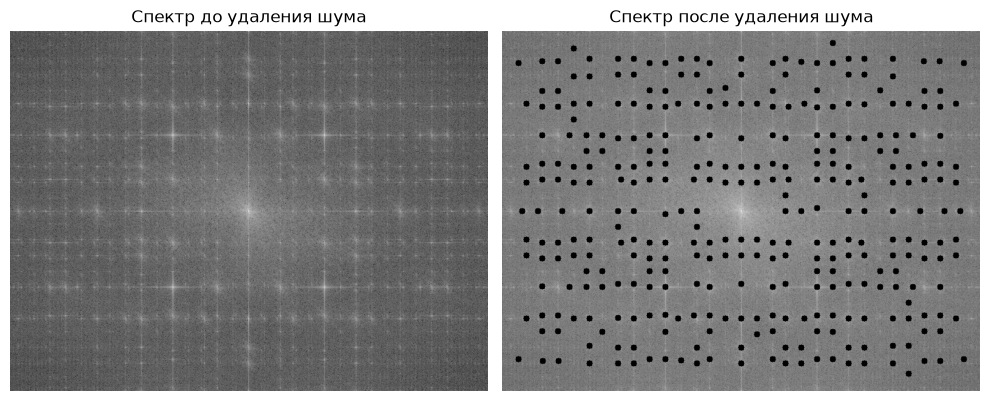

In [26]:
dft2 = cv.dft(np.float32(image), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift2 = np.fft.fftshift(dft2)
magnitude_spectrum2 = 20*np.log(cv.magnitude(dft_shift2[:,:,0], dft_shift2[:,:,1]) + 1)

local_maxima = peak_local_max(magnitude_spectrum2, min_distance=20, threshold_abs=180)

mask = np.ones((rows, cols, 2), dtype=np.uint8)
center_x, center_y = rows//2, cols//2
for peak in local_maxima:
    y, x = peak
    distance = np.sqrt((x - center_y)**2 + (y - center_x)**2)
    if distance > 40:  
        cv.circle(mask, (x, y), 5, (0, 0), -1)

dft_shift_filtered_noise = dft_shift2 * mask

magnitude_spectrum_after_noise = 20*np.log(cv.magnitude(dft_shift_filtered_noise[:,:,0],
                                                        dft_shift_filtered_noise[:,:,1]) + 1)
f_ishift2 = np.fft.ifftshift(dft_shift_filtered_noise)
img_back_noise = cv.idft(f_ishift2)
img_back_noise = cv.magnitude(img_back_noise[:,:,0], img_back_noise[:,:,1])

plt.figure(figsize=(10, 5))
plt.subplot(121)
plt.imshow(magnitude_spectrum2, cmap='gray')
plt.title("Спектр до удаления шума")
plt.axis('off')

plt.subplot(122)
plt.imshow(magnitude_spectrum_after_noise, cmap='gray')
plt.title("Спектр после удаления шума")
plt.axis('off')
plt.tight_layout()
plt.show()



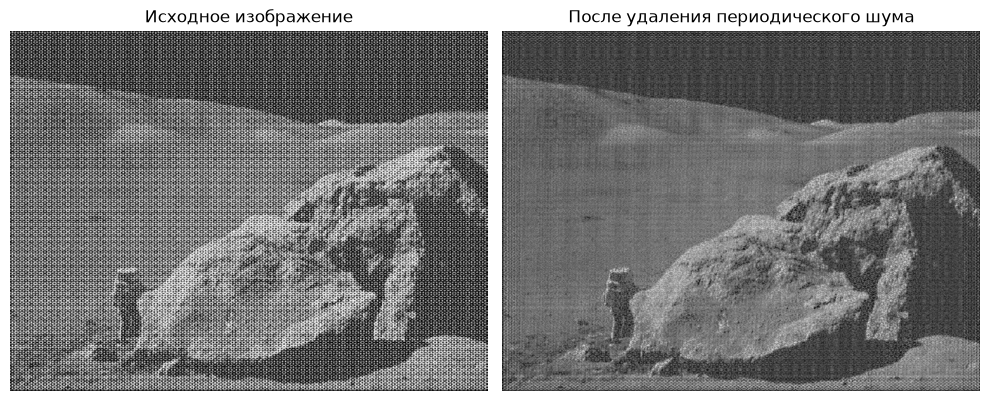

In [27]:
plt.figure(figsize=(10, 5))
plt.subplot(121)
plt.imshow(image, cmap='gray')
plt.title("Исходное изображение")
plt.axis('off')

plt.subplot(122)
plt.imshow(img_back_noise, cmap='gray')
plt.title("После удаления периодического шума")
plt.axis('off')
plt.tight_layout()
plt.show()